In [2]:
import pandas as pd
import requests, time

BASE = "https://blockstream.info/api"

selected = pd.read_pickle("data/selected_clusters.pkl")
print(len(selected))     # should match notebook 1: 6, or 8 if you added the mixer sets

row = selected.sort_values("n_tx").iloc[0]      # smallest set, for a first test
addr = row["addr_key"][0]                       # first address of that set, not printed

r = requests.get(f"{BASE}/address/{addr}", timeout=30)
r.raise_for_status()
print(row["cluster_id"], row["n_tx"], r.json()["chain_stats"]["tx_count"])

time.sleep(1)
r = requests.get(f"{BASE}/address/{addr}/txs", timeout=30)
r.raise_for_status()
txs = r.json()
print(len(txs), list(txs[0].keys()))
print(len(txs[0]["vin"]), len(txs[0]["vout"]))

8
45 37.0 11
11 ['txid', 'version', 'locktime', 'vin', 'vout', 'size', 'weight', 'fee', 'status']
13 2


In [3]:
print(row["n_addr"], row["n_tx"])

tot_tx = tot_txo = 0
for a in row["addr_key"]:
    r = requests.get(f"{BASE}/address/{a}", timeout=30)
    r.raise_for_status()
    s = r.json()["chain_stats"]
    tot_tx += s["tx_count"]
    tot_txo += s["funded_txo_count"] + s["spent_txo_count"]
    print(s["tx_count"], s["funded_txo_count"], s["spent_txo_count"])
    time.sleep(1)
print(tot_tx, tot_txo)

# bonus: is the queried address an input or an output of the first transaction?
t = txs[0]
print(any((v.get("prevout") or {}).get("scriptpubkey_address") == addr for v in t["vin"]),
      any(o.get("scriptpubkey_address") == addr for o in t["vout"]))

2.0 37.0
11 6 6
38 22 22
49 56
True False


In [4]:
import os, json

os.makedirs("data/raw", exist_ok=True)

def fetch_all_txs(addr, cache_name):
    path = f"data/raw/{cache_name}.json"
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    txs, last = [], None
    while True:
        url = f"{BASE}/address/{addr}/txs/chain" + (f"/{last}" if last else "")
        r = requests.get(url, timeout=30)
        r.raise_for_status()
        page = r.json()
        txs.extend(page)
        if len(page) < 25:
            break
        last = page[-1]["txid"]
        time.sleep(1)
    with open(path, "w") as f:
        json.dump(txs, f)
    return txs

In [5]:
snap = pd.Timestamp("2024-04-25", tz="UTC").timestamp()

all_txs, per_addr_total, after, recv_before = {}, 0, 0, 0
for i, a in enumerate(row["addr_key"]):
    txs_a = fetch_all_txs(a, f"c{row['cluster_id']}_a{i}")
    per_addr_total += len(txs_a)
    for t in txs_a:
        all_txs[t["txid"]] = t
        bt = t["status"].get("block_time") or 0
        if bt > snap:
            after += 1
        else:
            recv_before += sum(o["value"] for o in t["vout"] if o.get("scriptpubkey_address") == a)
    time.sleep(1)

print(per_addr_total, after, per_addr_total - after, row["n_tx"])
print(len(all_txs))
print(recv_before / 1e8, row["total_received"])

49 12 37 37.0
49
0.02902714 0.02902714


In [6]:
rows = []
for _, c in selected.iterrows():
    for i, a in enumerate(c["addr_key"]):
        r = requests.get(f"{BASE}/address/{a}", timeout=30)
        r.raise_for_status()
        rows.append({"cluster_id": c["cluster_id"], "addr_idx": i,
                     "tx_count_now": r.json()["chain_stats"]["tx_count"]})
        time.sleep(1)

dry = pd.DataFrame(rows)
print(len(dry), dry["tx_count_now"].sum(), (dry["tx_count_now"] // 25 + 1).sum())
print(dry.groupby("cluster_id")["tx_count_now"].sum())

11 6047 249
cluster_id
25     2315
43      103
45       49
104     268
149     293
157     304
209    1955
667     760
Name: tx_count_now, dtype: int64


In [7]:
def get_json(url, tries=5):
    for k in range(tries):
        r = requests.get(url, timeout=30)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 429 or r.status_code >= 500:
            time.sleep(10 * (k + 1))
            continue
        r.raise_for_status()
    raise RuntimeError("too many retries")

def fetch_all_txs(addr, cache_name):
    path = f"data/raw/{cache_name}.json"
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    txs, last = [], None
    while True:
        url = f"{BASE}/address/{addr}/txs/chain" + (f"/{last}" if last else "")
        page = get_json(url)
        txs.extend(page)
        if len(page) < 25:
            break
        last = page[-1]["txid"]
        time.sleep(1)
    with open(path, "w") as f:
        json.dump(txs, f)
    return txs

snap = pd.Timestamp("2024-04-25", tz="UTC").timestamp()
report = []
for _, c in selected.iterrows():
    before = recv_before = n_total = 0
    for i, a in enumerate(c["addr_key"]):
        txs_a = fetch_all_txs(a, f"c{c['cluster_id']}_a{i}")
        n_total += len(txs_a)
        for t in txs_a:
            if (t["status"].get("block_time") or 0) <= snap:
                before += 1
                recv_before += sum(o["value"] for o in t["vout"]
                                   if o.get("scriptpubkey_address") == a)
    report.append({"cluster_id": c["cluster_id"], "n_tx_dataset": c["n_tx"],
                   "n_before": before, "n_total": n_total,
                   "recv_dataset": c["total_received"], "recv_before": recv_before / 1e8})

rep = pd.DataFrame(report)
print(rep)

   cluster_id  n_tx_dataset  n_before  n_total  recv_dataset  recv_before
0          25        2118.0      2118     2315    428.570773   428.570773
1          43          89.0        89      103      0.121478     0.121478
2          45          37.0        37       49      0.029027     0.029027
3         104         253.0       253      268     37.648299    37.648299
4         149         262.0       262      293      0.357399     0.357399
5         157         304.0       304      304      1.339006     1.339006
6         209        1645.0      1645     1955     15.845226    15.845226
7         667         456.0       456      760      0.822595     0.822595


In [8]:
import glob, json

seed_to_cluster = {a: c["cluster_id"] for _, c in selected.iterrows() for a in c["addr_key"]}

tx_rows, flow_rows, seen = [], [], set()
for path in sorted(glob.glob("data/raw/c*_a*.json")):
    with open(path) as f:
        for t in json.load(f):
            if t["txid"] in seen:
                continue
            seen.add(t["txid"])
            tx_rows.append({"txid": t["txid"], "block_time": t["status"].get("block_time"),
                            "fee": t["fee"], "n_in": len(t["vin"]), "n_out": len(t["vout"])})
            for v in t["vin"]:
                p = v.get("prevout") or {}
                flow_rows.append({"txid": t["txid"], "side": "in",
                                  "addr": p.get("scriptpubkey_address"), "value": p.get("value")})
            for o in t["vout"]:
                flow_rows.append({"txid": t["txid"], "side": "out",
                                  "addr": o.get("scriptpubkey_address"), "value": o.get("value")})

txs = pd.DataFrame(tx_rows)
flows = pd.DataFrame(flow_rows)
flows["cluster_id"] = flows["addr"].map(seed_to_cluster)    # filled only for our seed addresses
txs["after_snap"] = txs["block_time"] > snap

print(len(txs), len(flows), flows["addr"].isna().sum())
print(txs["after_snap"].sum())
print(flows["addr"].nunique())

touch = flows.dropna(subset=["cluster_id"]).groupby("txid")["cluster_id"].nunique()
print((touch > 1).sum())

6045 141427 3
882
58555
2


In [9]:
per_set = flows.dropna(subset=["cluster_id"]).groupby("cluster_id")["txid"].nunique()
per_set.index = per_set.index.astype(int)
cmp = pd.DataFrame({"unique_tx": per_set, "n_total": rep.set_index("cluster_id")["n_total"]})
print(cmp)

link_ids = touch[touch > 1].index
for tid in link_ids:
    sub = flows[flows["txid"] == tid]
    ins  = sorted(int(x) for x in sub.loc[(sub["side"] == "in")  & sub["cluster_id"].notna(), "cluster_id"].unique())
    outs = sorted(int(x) for x in sub.loc[(sub["side"] == "out") & sub["cluster_id"].notna(), "cluster_id"].unique())
    t = txs[txs["txid"] == tid].iloc[0]
    print(ins, outs, t["n_in"], t["n_out"], t["fee"], pd.to_datetime(t["block_time"], unit="s", utc=True).date())

            unique_tx  n_total
cluster_id                    
25               2315     2315
43                103      103
45                 49       49
104               268      268
149               293      293
157               304      304
209              1955     1955
667               760      760
[] [104, 667] 1 19 10200 2024-06-03
[] [43, 149] 1 9 5170 2023-01-31


In [10]:
txs["size_rows"] = txs["n_in"] + txs["n_out"]
print(txs["size_rows"].describe())
print(txs["size_rows"].nlargest(10).tolist())

top1 = txs.nlargest(int(len(txs) * 0.01), "size_rows")["size_rows"].sum()
print(top1 / txs["size_rows"].sum())

count    6045.000000
mean       23.395699
std        65.515299
min         2.000000
25%         3.000000
50%         5.000000
75%         9.000000
max      1185.000000
Name: size_rows, dtype: float64
[1185, 650, 645, 637, 609, 559, 541, 532, 520, 502]
0.16536446364555565


In [11]:
p = (txs["n_in"] * txs["n_out"])
print(p.sum(), p.nlargest(5).tolist())

3399535 [39576, 21186, 21120, 21006, 20900]


In [12]:
import networkx as nx

f = flows.dropna(subset=["addr", "value"])
agg = f.groupby(["txid", "side", "addr"], as_index=False)["value"].sum()

addr_id = {a: f"A{i}" for i, a in enumerate(agg["addr"].unique())}
tx_id   = {t: f"T{i}" for i, t in enumerate(txs["txid"])}

G = nx.DiGraph()
for t, r in txs.set_index("txid").iterrows():
    G.add_node(tx_id[t], kind="tx", after_snap=bool(r["after_snap"]))
for a, nid in addr_id.items():
    G.add_node(nid, kind="addr", cluster=int(seed_to_cluster.get(a, -1)))
for r in agg.itertuples():
    if r.side == "in":
        G.add_edge(addr_id[r.addr], tx_id[r.txid], value=int(r.value))
    else:
        G.add_edge(tx_id[r.txid], addr_id[r.addr], value=int(r.value))

print(G.number_of_nodes(), G.number_of_edges())
print(sum(1 for _, d in G.nodes(data=True) if d["kind"] == "addr"),
      sum(1 for _, d in G.nodes(data=True) if d["kind"] == "tx"))

64600 109746
58555 6045


In [13]:
cnt = f.groupby(["txid", "side", "addr"]).size()
print(len(f), len(cnt), (cnt > 1).sum(), cnt.max())
print(cnt.nlargest(5).tolist())

141424 109746 7485 469
[469, 201, 201, 201, 201]


In [14]:
comps = sorted(nx.weakly_connected_components(G), key=len, reverse=True)
print(len(comps))
for c in comps:
    seeds = sorted({G.nodes[n]["cluster"] for n in c
                    if G.nodes[n]["kind"] == "addr" and G.nodes[n]["cluster"] >= 0})
    print(len(c), seeds)

2
64571 [25, 43, 45, 104, 149, 157, 209, 667]
29 [25]


In [15]:
addr_nodes = [n for n, d in G.nodes(data=True) if d["kind"] == "addr"]
deg = pd.Series({n: G.degree(n) for n in addr_nodes})
print(deg.describe())
print((deg == 1).mean())
top = deg.nlargest(10)
print([(int(v), G.nodes[n]["cluster"]) for n, v in top.items()])

count    58555.000000
mean         1.874238
std         15.184432
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max       2001.000000
dtype: float64
0.8973785330031594
[(2001, 25), (1955, 209), (760, 667), (500, -1), (462, -1), (449, -1), (406, -1), (395, -1), (381, -1), (373, -1)]


In [16]:
tx_nodes = [n for n, d in G.nodes(data=True) if d["kind"] == "tx"]

tx_sets = {}
for t in tx_nodes:
    nb = set(G.predecessors(t)) | set(G.successors(t))
    tx_sets[t] = {G.nodes[a]["cluster"] for a in nb if G.nodes[a]["cluster"] >= 0}

bridge = {}
for a in addr_nodes:
    if G.nodes[a]["cluster"] >= 0:
        continue
    reach = set()
    for t in set(G.predecessors(a)) | set(G.successors(a)):
        if len(tx_sets[t]) == 1:
            reach |= tx_sets[t]
    if len(reach) >= 2:
        bridge[a] = reach

print(len(bridge))
print(pd.Series([len(s) for s in bridge.values()]).value_counts())
print(sorted([(G.degree(a), sorted(int(x) for x in s)) for a, s in bridge.items()], reverse=True)[:10])

44
2    40
3     3
4     1
Name: count, dtype: int64
[(80, [43, 45, 149, 667]), (55, [43, 149]), (41, [25, 43]), (20, [43, 149]), (19, [149, 157]), (13, [149, 157]), (13, [43, 149, 157]), (12, [43, 667]), (10, [149, 209, 667]), (10, [43, 149])]


In [17]:
from itertools import combinations

ids = sorted(int(x) for x in selected["cluster_id"])
M = pd.DataFrame(0, index=ids, columns=ids)
for a, s in bridge.items():
    for x, y in combinations(sorted(int(v) for v in s), 2):
        M.loc[x, y] += 1
        M.loc[y, x] += 1
print(M)

     25   43   45   104  149  157  209  667
25     0    1    0    0    1    1    7    0
43     1    0    1    2   15    1    0    2
45     0    1    0    0    2    0    0    1
104    0    2    0    0    2    2    1    0
149    1   15    2    2    0    8    1    5
157    1    1    0    2    8    0    1    0
209    7    0    0    1    1    1    0    1
667    0    2    1    0    5    0    1    0


In [18]:
seed_nodes = {n for n in addr_nodes if G.nodes[n]["cluster"] >= 0}

def has_seed(nodes):
    return any(n in seed_nodes for n in nodes)

roles = {}
for a in bridge:
    r = dict(funds_seed=0, co_input=0, paid_by_seed=0, co_output=0)
    for t in G.successors(a):             # a is an input of t
        r["funds_seed"] += has_seed(G.successors(t))
        r["co_input"]   += has_seed(G.predecessors(t))
    for t in G.predecessors(a):           # a is an output of t
        r["paid_by_seed"] += has_seed(G.predecessors(t))
        r["co_output"]    += has_seed(G.successors(t))
    roles[a] = r

roles_df = pd.DataFrame(roles).T
print(roles_df.sum())
print((roles_df > 0).sum())

funds_seed      119
co_input         31
paid_by_seed     94
co_output       117
dtype: int64
funds_seed      15
co_input         3
paid_by_seed     6
co_output       36
dtype: int64


In [19]:
def seed_sets(nodes):
    return {G.nodes[x]["cluster"] for x in nodes if x in seed_nodes}

print("co-input bridges: [sets reached] [sets co-spent with] n_tx (in min,max) (out min,max)")
for a in bridge:
    if roles[a]["co_input"] == 0:
        continue
    ns, n_ins, n_outs = set(), [], []
    for t in G.successors(a):
        s = seed_sets(G.predecessors(t))
        if s:
            ns |= s
            row = txs.iloc[int(t[1:])]
            n_ins.append(int(row["n_in"])); n_outs.append(int(row["n_out"]))
    print(sorted(int(x) for x in bridge[a]), sorted(int(x) for x in ns), len(n_ins),
          (min(n_ins), max(n_ins)), (min(n_outs), max(n_outs)))

print("destination bridges: [sets reached] [sets paying it] n_payments")
for a in bridge:
    if roles[a]["paid_by_seed"] == 0:
        continue
    ns, n = set(), 0
    for t in G.predecessors(a):
        s = seed_sets(G.predecessors(t))
        if s:
            ns |= s
            n += 1
    print(sorted(int(x) for x in bridge[a]), sorted(int(x) for x in ns), n)

co-input bridges: [sets reached] [sets co-spent with] n_tx (in min,max) (out min,max)
[149, 157] [157] 18 (3, 27) (1, 2)
[149, 157] [157] 12 (5, 18) (1, 2)
[25, 157] [25] 1 (16, 16) (1, 1)
destination bridges: [sets reached] [sets paying it] n_payments
[43, 149] [43, 149] 20
[43, 149] [43, 149] 55
[43, 149] [43, 149] 3
[43, 149] [43, 149] 8
[43, 149] [43, 149] 6
[43, 149] [43, 149] 2


In [20]:
fl = flows.dropna(subset=["addr", "value"]).copy()
rows = []
for cid in sorted(int(x) for x in selected["cluster_id"]):
    mine = fl[fl["cluster_id"] == cid]
    tids = set(mine["txid"])
    sub = txs[txs["txid"].isin(tids)]
    others = fl[fl["txid"].isin(tids) & fl["cluster_id"].isna()]
    rows.append({
        "set": cid,
        "n_tx": len(tids),
        "first": pd.to_datetime(sub["block_time"].min(), unit="s", utc=True).date(),
        "last": pd.to_datetime(sub["block_time"].max(), unit="s", utc=True).date(),
        "recv_btc": round(mine.loc[mine["side"] == "out", "value"].sum() / 1e8, 4),
        "sent_btc": round(mine.loc[mine["side"] == "in", "value"].sum() / 1e8, 4),
        "median_fee": int(sub["fee"].median()),
        "counterparties": others["addr"].nunique(),
    })
summary = pd.DataFrame(rows).set_index("set")
print(summary)

     n_tx       first        last  recv_btc  sent_btc  median_fee  \
set                                                                 
25   2315  2018-01-08  2026-01-14  429.6823  429.6823      110000   
43    103  2021-02-07  2026-02-04    0.1335    0.1335        4388   
45     49  2021-11-27  2025-04-05    0.0309    0.0309        2530   
104   268  2016-06-09  2026-09-02   37.6535   37.6535        5470   
149   293  2020-09-30  2026-06-26    0.3673    0.3649        5275   
157   304  2018-07-21  2022-03-04    1.3390    1.3390       12600   
209  1955  2020-07-07  2026-10-06   15.9038   15.7739        4000   
667   760  2023-02-16  2026-08-02    1.4798    1.4798        4230   

     counterparties  
set                  
25            34813  
43             1663  
45              827  
104            6202  
149            5972  
157            2259  
209            2820  
667            4062  


In [21]:
pr = nx.pagerank(G)
pr_a = pd.Series({n: pr[n] for n in addr_nodes})
cmp_df = pd.DataFrame({"pagerank": pr_a, "degree": deg})
print(cmp_df["pagerank"].rank().corr(cmp_df["degree"].rank()))
print([(round(v * 1e3, 3), G.degree(n), G.nodes[n]["cluster"]) for n, v in pr_a.nlargest(10).items()])

-0.0009273925645532371
[(49.818, 131, -1), (17.317, 2001, 25), (6.143, 58, -1), (5.493, 21, -1), (5.199, 1955, 209), (3.3, 1, -1), (2.957, 2, -1), (2.957, 1, -1), (2.653, 6, -1), (2.554, 395, -1)]


In [22]:
per_set = []
for cid in sorted(int(x) for x in selected["cluster_id"]):
    tids = set(fl.loc[fl["cluster_id"] == cid, "txid"])
    sub = txs[txs["txid"].isin(tids)]
    rows_ = sub["n_in"] + sub["n_out"]
    per_set.append({"set": cid, "median_rows": int(rows_.median()),
                    "median_fee_per_row": int((sub["fee"] / rows_).median())})
print(pd.DataFrame(per_set).set_index("set"))

     median_rows  median_fee_per_row
set                                 
25             8               18333
43             5                 579
45             6                 322
104            3                1507
149            4                 680
157            5                2126
209            4                1000
667            4                 908


In [23]:
cmp_df["in_degree"] = pd.Series({n: G.in_degree(n) for n in addr_nodes})
print(cmp_df["pagerank"].rank().corr(cmp_df["in_degree"].rank()))

def med(xs):
    return float(pd.Series(xs).median()) if xs else None

print("set, paying txs, spending txs, median inputs, median outputs of paying txs")
for n in pr_a.nlargest(10).index:
    paying = list(G.predecessors(n))
    n_in  = [int(txs.iloc[int(t[1:])]["n_in"])  for t in paying]
    n_out = [int(txs.iloc[int(t[1:])]["n_out"]) for t in paying]
    print(G.nodes[n]["cluster"], len(paying), G.out_degree(n), med(n_in), med(n_out))

0.9780959070818321
set, paying txs, spending txs, median inputs, median outputs of paying txs
-1 131 0 147.0 11.0
25 1821 180 4.0 3.0
-1 58 0 47.5 1.0
-1 21 0 75.0 2.0
209 1948 7 1.0 3.0
-1 1 0 342.0 1.0
-1 1 1 518.0 2.0
-1 1 0 518.0 2.0
-1 6 0 23.0 2.0
-1 318 77 211.0 39.0


In [24]:
for n in pr_a.nlargest(10).index:
    if G.nodes[n]["cluster"] >= 0:
        continue
    touched = set()
    for t in G.predecessors(n):
        touched |= tx_sets[t]
    print(n in bridge, sorted(int(x) for x in touched), G.degree(n))

False [25] 131
False [25] 58
False [25] 21
False [104] 1
False [104] 2
False [104] 1
False [25] 6
False [25] 395


In [25]:
from itertools import combinations

ins = fl[fl["side"] == "in"]
rows, cos = [], {}
for cid in sorted(int(x) for x in selected["cluster_id"]):
    mine = {a for a, c in seed_to_cluster.items() if c == cid}
    tx_in = set(ins.loc[ins["addr"].isin(mine), "txid"])
    co = set(ins.loc[ins["txid"].isin(tx_in), "addr"]) - mine
    small = set(txs.loc[txs["n_out"] <= 2, "txid"]) & tx_in
    co_small = set(ins.loc[ins["txid"].isin(small), "addr"]) - mine
    cos[cid] = co
    rows.append({"set": cid, "txs_spending_seed": len(tx_in), "co_inputs": len(co),
                 "co_inputs_n_out_le_2": len(co_small),
                 "max_inputs_in_one_tx": int(txs.loc[txs["txid"].isin(tx_in), "n_in"].max()) if tx_in else 0})
print(pd.DataFrame(rows).set_index("set"))
print(sum(len(cos[x] & cos[y]) for x, y in combinations(cos, 2)))

     txs_spending_seed  co_inputs  co_inputs_n_out_le_2  max_inputs_in_one_tx
set                                                                          
25                 319       2966                  2629                   548
43                  46         20                    20                    40
45                  21         53                    53                    28
104                 20       3423                  3423                   643
149                 79         38                    38                    27
157                145        225                   225                    87
209                  7          0                     0                   201
667                245         96                    96                    38
0


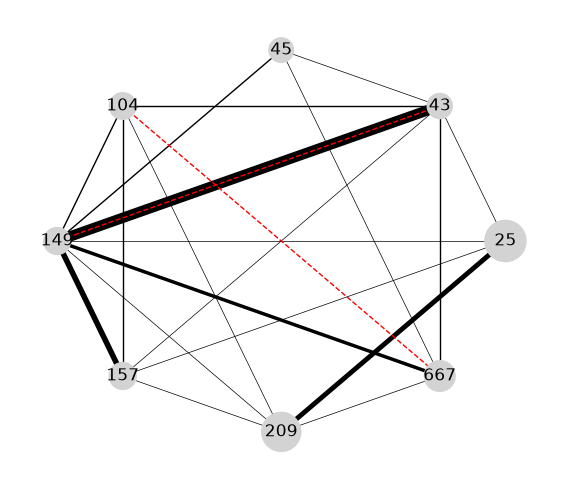

In [26]:
import matplotlib.pyplot as plt

H = nx.Graph()
for cid in ids:
    H.add_node(cid, n_tx=int(summary.loc[cid, "n_tx"]))
for x, y in combinations(ids, 2):
    if M.loc[x, y] > 0:
        H.add_edge(x, y, weight=int(M.loc[x, y]))
for x, y in [(104, 667), (43, 149)]:
    if not H.has_edge(x, y):
        H.add_edge(x, y, weight=0)
    H[x][y]["linked"] = True

pos = nx.circular_layout(H)
fig, ax = plt.subplots(figsize=(7, 6))
nx.draw_networkx_nodes(H, pos, node_size=[300 + H.nodes[n]["n_tx"] / 4 for n in H],
                       node_color="lightgray", ax=ax)
nx.draw_networkx_labels(H, pos, ax=ax)
b = [(u, v) for u, v, d in H.edges(data=True) if d["weight"] > 0]
nx.draw_networkx_edges(H, pos, edgelist=b, width=[H[u][v]["weight"] * 0.5 for u, v in b], ax=ax)
l = [(u, v) for u, v, d in H.edges(data=True) if d.get("linked")]
nx.draw_networkx_edges(H, pos, edgelist=l, style="dashed", edge_color="red", ax=ax)
ax.set_axis_off()
plt.savefig("sets_graph.png", dpi=150, bbox_inches="tight")
plt.show()

In [27]:
nx.write_gexf(G, "data/graph_full.gexf")

keep = set(bridge)
for a in bridge:
    for t in set(G.predecessors(a)) | set(G.successors(a)):
        keep.add(t)
        keep |= {x for x in set(G.predecessors(t)) | set(G.successors(t)) if x in seed_nodes}
sub = G.subgraph(keep).copy()
print(sub.number_of_nodes(), sub.number_of_edges())
nx.write_gexf(sub, "data/bridges_subgraph.gexf")

324 632


In [28]:
heavy = {(u, v): H[u][v]["weight"] for u, v in b if H[u][v]["weight"] >= 5}
nx.draw_networkx_edge_labels(H, pos, edge_labels=heavy, font_size=9, ax=ax)

{(25, 209): Text(0.49999722434244354, -0.5000027632416031, '7'),
 (43, 149): Text(-0.14644013434210978, 0.35355602196732816, '15'),
 (149, 157): Text(-0.8535541635619762, -0.3535514441943177, '8'),
 (149, 667): Text(-0.14645309581661348, -0.35355078810783147, '5')}

In [29]:
from collections import Counter
print(Counter(d["kind"] for _, d in sub.nodes(data=True)))
print(sorted(Counter(d["cluster"] for _, d in sub.nodes(data=True) if d["kind"] == "addr").items()))

Counter({'tx': 271, 'addr': 53})
[(-1, 44), (25, 2), (43, 1), (45, 1), (104, 1), (149, 1), (157, 1), (209, 1), (667, 1)]


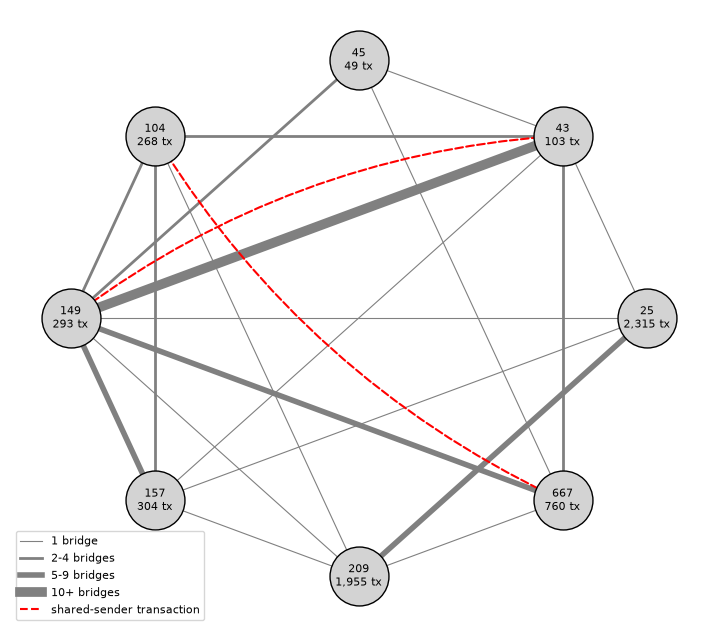

In [30]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(9, 8))
pos = nx.circular_layout(H)

nx.draw_networkx_nodes(H, pos, node_size=1800, node_color="lightgray",
                       edgecolors="black", ax=ax)
nx.draw_networkx_labels(H, pos, labels={n: f"{n}\n{H.nodes[n]['n_tx']:,} tx" for n in H},
                        font_size=8, ax=ax)

def wclass(w):
    return 0.8 if w == 1 else 2 if w < 5 else 4 if w < 10 else 7

for u, v, d in H.edges(data=True):
    if d["weight"] > 0:
        nx.draw_networkx_edges(H, pos, edgelist=[(u, v)], width=wclass(d["weight"]),
                               edge_color="gray", ax=ax)
for u, v, d in H.edges(data=True):
    if d.get("linked"):
        nx.draw_networkx_edges(H, pos, edgelist=[(u, v)], width=1.5, style="dashed",
                               edge_color="red", arrows=True, arrowstyle="-",
                               connectionstyle="arc3,rad=0.15", ax=ax)

ax.legend(handles=[
    Line2D([0], [0], color="gray", lw=0.8, label="1 bridge"),
    Line2D([0], [0], color="gray", lw=2, label="2-4 bridges"),
    Line2D([0], [0], color="gray", lw=4, label="5-9 bridges"),
    Line2D([0], [0], color="gray", lw=7, label="10+ bridges"),
    Line2D([0], [0], color="red", lw=1.5, ls="--", label="shared-sender transaction")],
    loc="lower left", fontsize=8)
ax.set_axis_off()
plt.savefig("sets_graph.png", dpi=150, bbox_inches="tight")
plt.show()

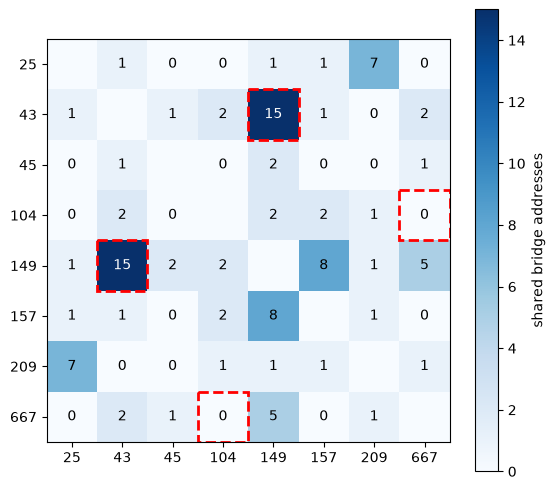

In [31]:
fig, ax = plt.subplots(figsize=(6.5, 6))
im = ax.imshow(M.values, cmap="Blues")
ax.set_xticks(range(len(ids))); ax.set_xticklabels(ids)
ax.set_yticks(range(len(ids))); ax.set_yticklabels(ids)
for i in range(len(ids)):
    for j in range(len(ids)):
        if i != j:
            ax.text(j, i, int(M.values[i, j]), ha="center", va="center",
                    color="white" if M.values[i, j] > 8 else "black")
for x, y in [(104, 667), (43, 149)]:
    i, j = ids.index(x), ids.index(y)
    for r_, c_ in [(i, j), (j, i)]:
        ax.add_patch(plt.Rectangle((c_ - 0.5, r_ - 0.5), 1, 1, fill=False,
                                   edgecolor="red", linewidth=2, linestyle="--"))
fig.colorbar(im, ax=ax, label="shared bridge addresses")
plt.savefig("sets_matrix.png", dpi=150, bbox_inches="tight")
plt.show()